# Tarea 2
##### Link github: https://github.com/nvrrou/RdPI_T2
#### Nombre: Cristóbal Navarro



## Instrucciones de ejecución
Asegurandose de tener la imagen en la ruta /[Carpeta_donde_se_encuentra_la_tarea]/rice.png la ejecución es apretar `Ejecutar todo`, así ejecutando todas las celdas en orden.

### Descripción de la tarea

En esta tarea se extraerán distintas caracteristicas cromáticas de la imagen llamada `rice.png`, sacaremos las siguientes caracteristicas:
- Color promedio.
- Gradiente promedio.
- Contraste.
- Momentos de HU en **escala de grises**.


### Importaciones previas
Para iniciar, se importarán las librerías necesarias:

In [182]:
%pip install pandas opencv-python matplotlib scikit-learn numpy


[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


Luego de esto, importaremos la imagen:

In [183]:
import cv2

img = cv2.imread('rice.png')

img = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)


A su vez, haremos la tabla para el dataframe que rellenaremos luego con `Pandas`:

In [184]:
datos = {'Color_Promedio': [],
         'Gradiente_Promedio': [],
         'Contraste':[],
         'Momentos de Hu':[[] for _ in range(7)] # 7 Momentos de Hu
         }


## **Desarrollo**



#### **Binarización de la imagen**
Para obtener el valor del gradiente promedio, primero debemos **binarizar** la imagen, esto se hará por dos partes, cortando la imagen desde el pixel 600, utilizando dos umbrales, 150 para la parte superior (como es recomendado en la pauta) y 128 para la inferior, ya que manualmente se visualiza  menos ruido con este umbral. 

De esta manera, se obtiene el siguiente resultado:

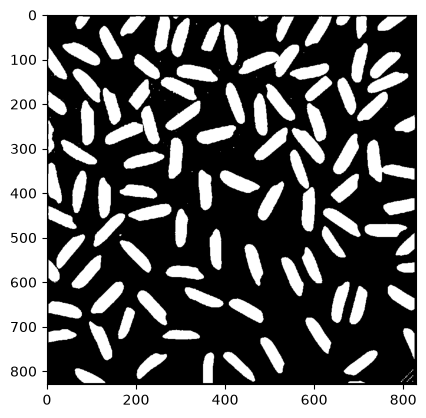

In [185]:
import matplotlib.pyplot as plt
corte = 600

binary = img.copy() #Dejamos img intacta
_, binary[:corte] = cv2.threshold(
    img[:corte], 150, 255, cv2.THRESH_BINARY
)
_, binary[corte:] = cv2.threshold(
    img[corte:], 128, 255, cv2.THRESH_BINARY
)

plt.imshow(binary, cmap="gray")
plt.show()

### Selección y limpieza de regiones 
La selección de regiones se hará **excluyendo** granos recortados, es decir, granos con coordenadas en el borde de la imagen. Esta seleccion se hará utilizando la función `cv2.findContours()`.

Luego se filtrarán aquellos que toquen el borde, con un umbral de 5 pixeles.

Y por ultimo, se filtraran aquellos con areas menores o iguales al 10% del promedio, esto para deshacernos del ruido restante en la imagen.

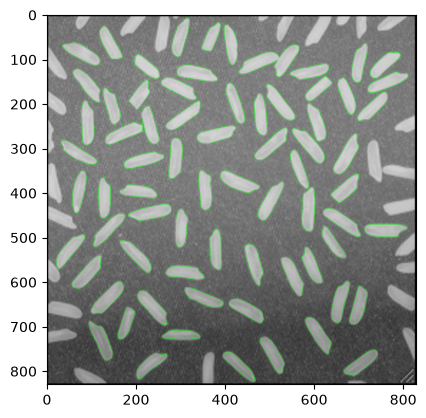

              Se encontraron  71  granos de arroz


In [186]:
contours, _ = cv2.findContours(binary, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_NONE)

resultado = cv2.cvtColor(img, cv2.COLOR_GRAY2BGR)

alto = len(binary)
ancho = len(binary[0])
filtrado_p1 = [] # Filtrado por borde
for contorno in contours:
    x = contorno[:, 0, 0]  # Columnas
    y = contorno[:, 0, 1]  # Filas (cv2 usa (x,y) = (Columna, Fila))

    toca_borde = (
        (x <= 5).any() # .any() da Verdadero si cualquiera de los elementos cumple la condición
        or (x >= ancho - 6).any()
        or (y <= 5).any()
        or (y >= alto - 6).any()
    )


    if not toca_borde:
        filtrado_p1.append(contorno)

filtrado_p2 = [] # Filtrado por area (eliminar ruido)
promedio_area = 0
for contorno in filtrado_p1: # Area promedio (p1)
    momentos = cv2.moments(contorno)
    area = momentos["m00"]
    promedio_area += area

promedio_area /= len(filtrado_p1)

for contorno in filtrado_p1: # Filtrado respecto al promedio (p2) c:
    momentos = cv2.moments(contorno)
    area = momentos["m00"]
    if area > promedio_area * 0.1:
        filtrado_p2.append(contorno)

cv2.drawContours(resultado, filtrado_p2, -1, (0, 255, 0), 1)

plt.imshow(resultado)
plt.show()

print("              Se encontraron ", len(filtrado_p2), " granos de arroz")
# se ve lindo en mi pc, perdón si no se ve lindo en el suyo...


##### **Problemas**
Como unico problema, se puede observar el arroz en ($i$,$j$) = (300, 700) (aprox.), el cual, está, según el umbral utilizado, conectado a al arroz cortado por el borde de la imagen. Dado que la unica solución pensada es seleccionarlo manualmente, se decide **ignorar** el caso y considerarlo parte del arroz que toca el borde, por ende, externo al conjunto a evaluar.

#### Etiquetación de cada grano
A pedido de la rubrica se etiquetará cada grano, para así entender de mejor manera los resultados.

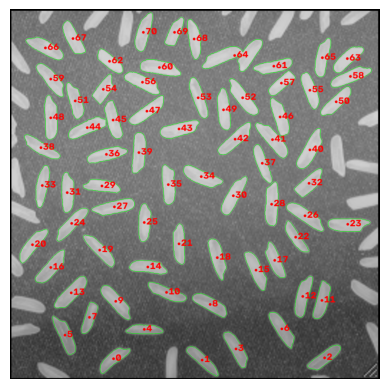

In [187]:
img_enum = img.copy()
img_enum = cv2.cvtColor(img_enum, cv2.COLOR_GRAY2BGR)

# Calculo de centro de masa y enumeración
for i, contorno in enumerate(filtrado_p2):
    # Obtener un punto dentro/cerca del contorno
    M = cv2.moments(contorno)
    cv2.drawContours(img_enum, [contorno], -1, (0, 255, 0), 1)

    if M["m00"] != 0:
        x = int(M["m10"] / M["m00"])
        y = int(M["m01"] / M["m00"])
    else:
        x, y = contorno[0][0]

    cv2.circle(img_enum, (x, y), 3, (255, 0, 0), -1)

    cv2.putText(
        img_enum,
        str(i),
        (x + 5, y+5),
        cv2.FONT_HERSHEY_SIMPLEX,
        0.7,
        (255, 0, 0),
        2
    )

plt.imshow(img_enum) 
plt.axis("off")
plt.show()

##### **Problemas**
De esta manera se puede observar que el arroz 64 son dos arroces, así que, por simplicidad, será **eliminado** del conjunto. Dado que `contours` es una *tupla*, debemos convertirla a lista para efectuar la eliminación.

In [188]:
filtrado_p2 = list(filtrado_p2)

del filtrado_p2[64]

Obtendremos la siguiente enumeración:

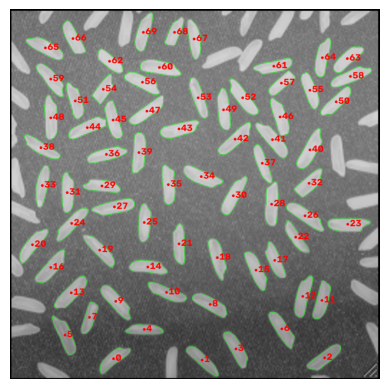

In [ ]:
img_enum_2 = img.copy()
img_enum_2 = cv2.cvtColor(img_enum_2, cv2.COLOR_GRAY2BGR)

# Calculo de centro de masa y enumeración
for i, contorno in enumerate(filtrado_p2):
    # Obtener un punto dentro/cerca del contorno
    M = cv2.moments(contorno)
    cv2.drawContours(img_enum_2, [contorno], -1, (0, 255, 0), 1)

    if M["m00"] != 0:
        x = int(M["m10"] / M["m00"])
        y = int(M["m01"] / M["m00"])
    else:
        x, y = contorno[0][0]

    cv2.circle(img_enum_2, (x, y), 3, (255, 0, 0), -1)

    cv2.putText(
        img_enum_2,
        str(i),
        (x + 5, y+5),
        cv2.FONT_HERSHEY_SIMPLEX,
        0.7,
        (255, 0, 0),
        2
    )

plt.imshow(img_enum_2)
plt.axis("off")
plt.show()

De esta manera, se mantuvo la integridad de los datos, con una perdida de datos total igual a 2 arroces.


### **Color promedio**
Para esto utilizaremos la función `.mean()`, con la imagen en **escala de grises**.


In [190]:
import numpy as np

colores_promedio = []

for contorno in filtrado_p2:
    mascara = np.zeros_like(img)

    cv2.drawContours(mascara, [contorno], -1, 255, -1)  # Rellenar el contorno en la máscara

    promedio = cv2.mean(img, mask=mascara)[0]  # Tomamos el primer (y único) valor del promedio de la imagen dentro del contorno

    colores_promedio.append(promedio) #Almacenamos

    print("Color promedio del contorno ", len(colores_promedio)-1, ": ", round(promedio,2))


datos["Color_Promedio"] = [] # Para que no hayan duplicados al volver a ejecutar.
datos["Color_Promedio"] = colores_promedio # Almacenamos los datos.


Color promedio del contorno  0 :  153.01
Color promedio del contorno  1 :  144.56
Color promedio del contorno  2 :  142.18
Color promedio del contorno  3 :  150.88
Color promedio del contorno  4 :  151.0
Color promedio del contorno  5 :  140.61
Color promedio del contorno  6 :  153.65
Color promedio del contorno  7 :  155.08
Color promedio del contorno  8 :  158.81
Color promedio del contorno  9 :  167.42
Color promedio del contorno  10 :  160.29
Color promedio del contorno  11 :  157.51
Color promedio del contorno  12 :  162.18
Color promedio del contorno  13 :  166.63
Color promedio del contorno  14 :  178.84
Color promedio del contorno  15 :  176.54
Color promedio del contorno  16 :  171.26
Color promedio del contorno  17 :  177.54
Color promedio del contorno  18 :  177.94
Color promedio del contorno  19 :  179.32
Color promedio del contorno  20 :  184.47
Color promedio del contorno  21 :  181.08
Color promedio del contorno  22 :  176.56
Color promedio del contorno  23 :  183.1
Colo

### **Gradiente promedio**


### Calculo de Gradiente Promedio
Luego de obtenida la imagen se hará el calculo del gradiente promedio, mediante las siguientes formulas:

- **Gradiente individual** ($\nabla$):
  $$
  \nabla L(x,y) = \sqrt{L_y^2+L_x^2}
  $$
  - Donde:
    - $L_x=-\frac{1}{2}L(x-1,y) + \frac{1}{2}L(x+1,y)$ 
    - $L_y=-\frac{1}{2}L(x,y-1) + \frac{1}{2}L(x,y+1)$ 
- **Gradiente promedio del perímetro de cada región**:
  $$
  \nabla L = \frac{\sum_{x,y \in R}^m \nabla L(x,y)}{m}
  $$
  - Donde $R$ es el conjunto de puntos del perímetro y $m$ es su cantidad.

*Las coordenadas son representadas como **x** y **y** ya que en mis apuntes de Obsidian así lo hice.*

Se calcularán las derivadas sobre la imagen en escala de grises con `np.gradient()`, que devuelve primero el cambio por filas (`Ly`) y luego por columnas (`Lx`). La magnitud se obtiene con `np.sqrt(Lx**2 + Ly**2)` y se promedia en los puntos del perímetro de cada grano filtrado.

In [191]:
import numpy as np

imagen = img.astype(float)

gy, gx = np.gradient(imagen)

# Se calcula la magnitud del gradiente en cada pixel
magnitud = np.sqrt(gx**2 + gy**2)

gradientes_promedio = []

for contorno in filtrado_p2:
    x = contorno[:, 0, 0] # Columnas 
    y = contorno[:, 0, 1] # Filas 

    valores = magnitud[y, x]  # NumPy indexa con [fila, columna] por eso se dan vuelta c:
    promedio = valores.mean()

    gradientes_promedio.append(float(promedio))

datos["Gradiente_Promedio"] = [] # Para que no hayan duplicados al volver a ejecutar.
datos["Gradiente_Promedio"] = gradientes_promedio # Almacenamos los datos.

print("Gradientes promedio: ", gradientes_promedio)

Gradientes promedio:  [15.395903397926366, 12.577700150911543, 13.241969464314256, 15.596054023098066, 12.675840998110493, 13.034319851962314, 16.46285170413987, 15.502607577459932, 18.27606805754772, 18.36676706245782, 16.634275497372478, 17.053763003109005, 18.004828234594985, 19.77878798984936, 16.373407023905173, 18.04920278229316, 17.46847533047812, 17.33400568183283, 17.758293045501976, 17.200032456861386, 19.033062073179327, 17.60151978614906, 15.604330255475478, 17.437549002395677, 16.978150851275483, 17.40976973862807, 18.64617466648522, 17.554131538082952, 19.633378936073907, 16.743525756729127, 17.88252628185937, 16.30119460853502, 18.958212079121413, 17.53429260157635, 17.392837317085956, 16.899276264515144, 17.297609691720297, 18.21078496889308, 17.251245980184635, 17.251307579016274, 18.751159252790178, 19.02651091738427, 19.2218711689758, 16.664820021505392, 17.974888382826258, 17.30521558656355, 18.720617281407925, 18.02185720359568, 19.52047101256563, 17.44819659008309

### Calculo de Contraste
Para calcular este valor en cada uno de los arroces, se debe definir qué se tomará como *vecindad*. 

En este caso, se tomará una región de aproximadamente 5 pixeles alrededor del arroz. Este valor no es exacto ya que la región será definida por la función `cv2.dilate(matriz, kernel)` la cual toma una matriz y la expante/dilata dependiendo de un kernel, es decir, si kernel es un circulo, se expande circularmente. Dentro de la implementación, se utilizó `cv2.MORPH_ELLIPSE` ya que la elipse es la figura más parecida al arroz dentro de las imagenes.

Para obtener la region interior, se utilizó `cv2.FILLED` llenando así la región dentro del contorno y así tomando en cuenta todo el arroz.

In [192]:
contrastes = []

radio = 5
kernel = cv2.getStructuringElement(
    cv2.MORPH_ELLIPSE,
    (2 * radio + 1, 2 * radio + 1)
) # Matriz de 11x11 con un elipse radio 5


cont = 1
for contorno in filtrado_p2:
    # Mascara del interior del contorno
    mascara = np.zeros_like(img, dtype=np.uint8)
    cv2.drawContours(mascara, [contorno], -1, 255, cv2.FILLED)  # Rellenar el contorno
    

    # se expande la mascara, para obtener el borde exterior del contorno
    mascara_dilatada = cv2.dilate(mascara, kernel) 
    exterior = (mascara_dilatada > 0) & (mascara == 0) # Borde exterior

    dentro = img[mascara > 0] # Pixeles dentro del contorno
    fuera = img[exterior] # Pixeles fuera del contorno

    media_dentro = float(dentro.mean())
    media_fuera = float(fuera.mean()) if fuera.size else np.nan #Si no hay pixeles fuera, se asigna NaN, no se dá el caso

    contrastes.append(media_dentro - media_fuera) #hacemos el calculo del contraste y lo almacenamos en la lista
    print(f"Contraste del contorno {cont}: {round((media_dentro - media_fuera), 2)}")
    cont += 1

datos["Contraste"] = [] # Para que no hayan duplicados.
datos["Contraste"] = contrastes # Almacenamos los datos.


Contraste del contorno 1: 62.77
Contraste del contorno 2: 57.72
Contraste del contorno 3: 53.28
Contraste del contorno 4: 63.87
Contraste del contorno 5: 57.68
Contraste del contorno 6: 51.82
Contraste del contorno 7: 65.78
Contraste del contorno 8: 63.09
Contraste del contorno 9: 63.32
Contraste del contorno 10: 69.57
Contraste del contorno 11: 58.86
Contraste del contorno 12: 67.02
Contraste del contorno 13: 68.76
Contraste del contorno 14: 66.43
Contraste del contorno 15: 63.34
Contraste del contorno 16: 67.7
Contraste del contorno 17: 57.25
Contraste del contorno 18: 64.83
Contraste del contorno 19: 63.66
Contraste del contorno 20: 61.59
Contraste del contorno 21: 61.98
Contraste del contorno 22: 62.59
Contraste del contorno 23: 58.94
Contraste del contorno 24: 64.17
Contraste del contorno 25: 59.67
Contraste del contorno 26: 64.88
Contraste del contorno 27: 64.63
Contraste del contorno 28: 61.11
Contraste del contorno 29: 64.08
Contraste del contorno 30: 61.45
Contraste del contor

### Calculo de Momentos de Hu
Finalmente procederemos con el calculo de los 7 primeros **momentos de Hu**, de los cuales las formulas de los 3 ultimos serán definidas (debido a que los 4 primeros ya están en la tarea 1):

#### Codigo primeros 4 momentos de Hu

In [193]:
def prim_m_hu(etas):
  momento = etas["nu20"] + etas["nu02"]
  return momento

def seg_m_hu(etas):
  momento = (etas["nu20"] - etas["nu02"])**2 + 4*(etas["nu11"])**2
  return momento

def ter_m_hu(etas):
  momento = (etas["nu30"]-3*etas["nu12"])**2 + (3*etas["nu21"]-etas["nu03"])**2
  return momento

def cuar_m_hu(etas):
  momento = (etas["nu30"] + etas["nu12"])**2 + (etas["nu21"] + etas["nu03"])**2
  return momento

#### 5to momento de Hu

$$
\begin{aligned}
\phi_5 ={}&
(\eta_{30}-3\eta_{12})(\eta_{30}+\eta_{12})
\left[(\eta_{30}+\eta_{12})^2-3(\eta_{21}+\eta_{03})^2\right] \\
&+ (3\eta_{21}-\eta_{03})(\eta_{21}+\eta_{03})
\left[3(\eta_{30}+\eta_{12})^2-(\eta_{21}+\eta_{03})^2\right]
\end{aligned}
$$

In [194]:
def quin_m_hu(etas):
  momento = (
    (etas["nu30"] - 3*etas["nu12"])*(etas["nu30"] + etas["nu12"])
    *((etas["nu30"] + etas["nu12"])**2 - 3*(etas["nu21"] + etas["nu03"])**2)
    + (3*etas["nu21"] - etas["nu03"])*(etas["nu21"] + etas["nu03"])
    *(3*(etas["nu30"] + etas["nu12"])**2 - (etas["nu21"] + etas["nu03"])**2)
  )
  return momento

#### 6to momento de Hu

$$
\begin{aligned}
\phi_6 ={}&
(\eta_{20}-\eta_{02})
\left[(\eta_{30}+\eta_{12})^2-(\eta_{21}+\eta_{03})^2\right] \\
&+4\eta_{11}(\eta_{30}+\eta_{12})(\eta_{21}+\eta_{03})
\end{aligned}
$$

In [195]:
def sex_m_hu(etas):
  momento = (
    (etas["nu20"] - etas["nu02"])
    *((etas["nu30"] + etas["nu12"])**2 - (etas["nu21"] + etas["nu03"])**2)
    + 4*etas["nu11"]*(etas["nu30"] + etas["nu12"])*(etas["nu21"] + etas["nu03"])
  )
  return momento

#### 7mo momento de Hu

$$
\begin{aligned}
\phi_7 ={}&
(3\eta_{21}-\eta_{03})(\eta_{30}+\eta_{12})
\left[(\eta_{30}+\eta_{12})^2-3(\eta_{21}+\eta_{03})^2\right] \\
&-(\eta_{30}-3\eta_{12})(\eta_{21}+\eta_{03})
\left[3(\eta_{30}+\eta_{12})^2-(\eta_{21}+\eta_{03})^2\right]
\end{aligned}
$$

In [196]:
def sep_m_hu(etas):
  momento = (
    (3*etas["nu21"] - etas["nu03"])*(etas["nu30"] + etas["nu12"])
    *((etas["nu30"] + etas["nu12"])**2 - 3*(etas["nu21"] + etas["nu03"])**2)
    - (etas["nu30"] - 3*etas["nu12"])*(etas["nu21"] + etas["nu03"])
    *(3*(etas["nu30"] + etas["nu12"])**2 - (etas["nu21"] + etas["nu03"])**2)
  )
  return momento

Con todas las funciones definidas, se hará el calculo según los contornos filtrados anteriormente, para esto utilizaremos los momentos calculadosm pero cada bit tendrá su intensidad de gris (de 0 a 255) para esto utilizamos `np.where()` la cual recibe como parametro nuestra imagen y nuestra mascara, en caso de que nuestra mascara sea mayor a 0 en la imagen, se queda con la intensidad dentro de esta, de no ser así se reemplazará con 0:

In [201]:
import cv2
import numpy as np

funciones_hu = [
    prim_m_hu,
    seg_m_hu,
    ter_m_hu,
    cuar_m_hu,
    quin_m_hu,
    sex_m_hu,
    sep_m_hu
]

# Evita duplicados al ejecutar otra vez.
datos["Momentos de Hu"] = [[] for _ in range(7)]

for contorno in filtrado_p2:
    # Seleccionar el interior del grano.
    mascara = np.zeros_like(img, dtype=np.uint8)
    cv2.drawContours(mascara, [contorno], -1, 255, cv2.FILLED)

    # Conservar los grises del grano y dejar el exterior en cero.
    grano = np.where(mascara > 0, img, 0)

    # Obtener momentos centrales normalizados usando las intensidades.
    etas = cv2.moments(grano, binaryImage=False)

    # Calcular y almacenar los siete momentos de Hu.
    for i, funcion in enumerate(funciones_hu):
        momento = funcion(etas)
        datos["Momentos de Hu"][i].append(momento)
        print(f"Momento de Hu {i+1} del contorno {len(datos['Momentos de Hu'][i])}: {momento}")

Momento de Hu 1 del contorno 1: 0.0018050492533366702
Momento de Hu 2 del contorno 1: 2.0985061046767213e-06
Momento de Hu 3 del contorno 1: 4.62332635083606e-10
Momento de Hu 4 del contorno 1: 5.158275931440974e-11
Momento de Hu 5 del contorno 1: -2.5820400306214957e-21
Momento de Hu 6 del contorno 1: -4.019852166276341e-14
Momento de Hu 7 del contorno 1: 7.535809296489957e-21
Momento de Hu 1 del contorno 2: 0.0024596601673491534
Momento de Hu 2 del contorno 2: 4.814734996163442e-06
Momento de Hu 3 del contorno 2: 3.2208910768895925e-10
Momento de Hu 4 del contorno 2: 1.76726718193182e-10
Momento de Hu 5 del contorno 2: 4.1875509466142786e-20
Momento de Hu 6 del contorno 2: 3.62350019529727e-13
Momento de Hu 7 del contorno 2: -4.9234930436976436e-21
Momento de Hu 1 del contorno 3: 0.002030821284641179
Momento de Hu 2 del contorno 3: 2.831760707022825e-06
Momento de Hu 3 del contorno 3: 8.84959492673861e-11
Momento de Hu 4 del contorno 3: 1.46114087137748e-11
Momento de Hu 5 del contor

### Recopilación de datos con Pandas
Ya obtenidos todos los datos se adjuntan en Pandas mediante el uso del diccionario creado al inicio de la tarea.

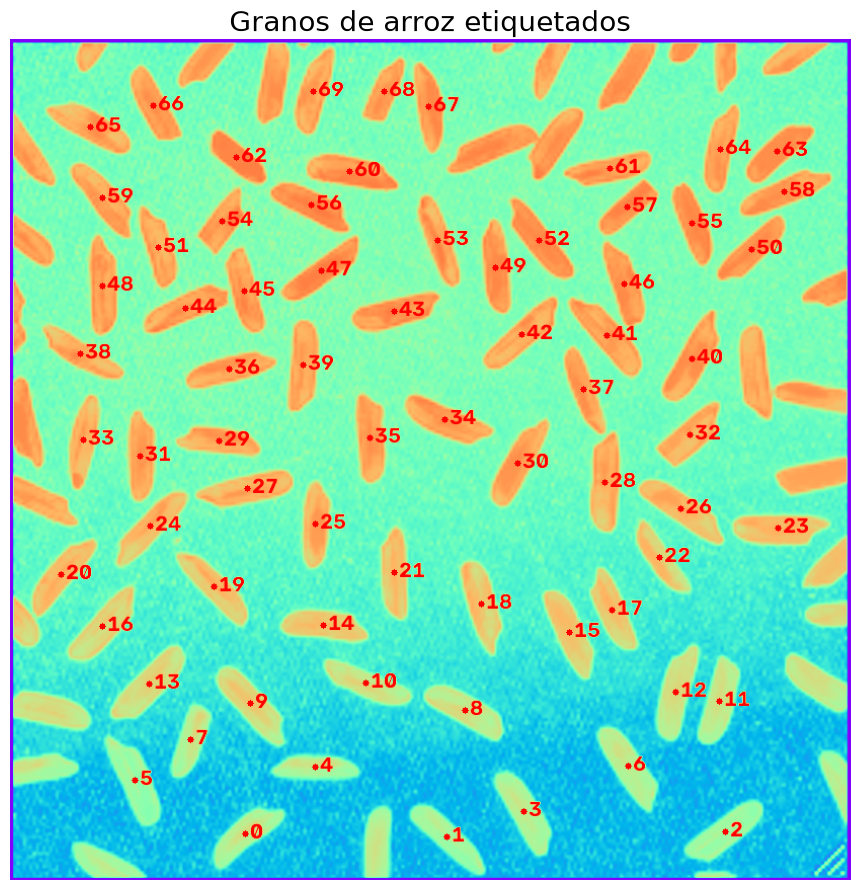

,Color_Promedio,Gradiente_Promedio,Contraste,Hu_1,Hu_2,Hu_3,Hu_4,Hu_5,Hu_6,Hu_7
Grano,,,,,,,,,,
0,153.005750,15.395903,62.772034,0.001805,2.098506e-06,4.623326e-10,5.158276e-11,-2.582040e-21,-4.019852e-14,7.535809e-21
1,144.564132,12.577700,57.715974,0.002460,4.814735e-06,3.220891e-10,1.767267e-10,4.187551e-20,3.623500e-13,-4.923493e-21
2,142.177649,13.241969,53.275393,0.002031,2.831761e-06,8.849595e-11,1.461141e-11,2.983178e-22,6.142328e-15,4.325091e-22
3,150.880834,15.596054,63.874763,0.001948,2.670458e-06,1.188280e-10,1.189294e-11,-2.672196e-22,-1.546661e-14,-3.584432e-22
4,150.995784,12.675841,57.679888,0.002164,3.581030e-06,1.862802e-10,3.086986e-11,7.452499e-22,-4.589807e-15,-2.219116e-21
5,140.609986,13.034320,51.819250,0.002138,3.170219e-06,3.149036e-10,2.954181e-11,-2.449125e-21,-4.853513e-14,1.456204e-21
6,153.646353,16.462852,65.777346,0.001894,2.514522e-06,2.827937e-11,4.858364e-12,3.724386e-23,1.382242e-16,-4.307948e-23
7,155.080591,15.502608,63.090774,0.001809,2.222556e-06,1.047025e-10,4.318195e-11,2.820078e-21,5.535196e-14,-6.912770e-22
8,158.814020,18.276068,63.320011,0.001705,1.897918e-06,7.234138e-11,6.554430e-12,-1.101779e-22,-8.062572e-15,-9.072403e-23


In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

# Mostrar en grande la imagen que ya etiquetaste.
plt.figure(figsize=(9, 9))
plt.imshow(img_enum_2)
plt.title("Granos de arroz etiquetados", fontsize=20)
plt.axis("off")
plt.tight_layout()
plt.show()

# Preparar una columna por característica.
datos_tabla = {
    "Color_Promedio": datos["Color_Promedio"],
    "Gradiente_Promedio": datos["Gradiente_Promedio"],
    "Contraste": datos["Contraste"]
}

for i in range(7):
    datos_tabla[f"Hu_{i+1}"] = datos["Momentos de Hu"][i]

# Cada fila corresponde a un grano, en el orden de filtrado_p2.
df = pd.DataFrame(datos_tabla)
df.index.name = "Grano"

# Mostrar todos los granos y columnas.
with pd.option_context("display.max_rows", None, "display.max_columns", None):
    display(df)



### Comentarios finales
Me gustan las tareas de este ramo. Gracias por darlo profe.

# Referencias

Documentación oficial de las funciones utilizadas:

- OpenCV. [Drawing Functions](https://docs.opencv.org/4.x/d6/d6e/group__imgproc__draw.html): relleno de regiones con `cv2.drawContours()` y `cv2.FILLED`.
- OpenCV. [Morphological Transformations](https://docs.opencv.org/4.x/d9/d61/tutorial_py_morphological_ops.html): `cv2.dilate()` y `cv2.getStructuringElement()`, utilizadas para construir la vecindad exterior con un kernel de tipo `cv2.MORPH_ELLIPSE`.
- NumPy. [numpy.gradient](https://numpy.org/doc/stable/reference/generated/numpy.gradient.html): cálculo de las derivadas por filas y columnas.

